# Part 2: Classification Model

**Candidate Name:** Matteo Antony Mistretta

**Date:** 2026-10-17

**Environment:** Python 3.14, PyTorch 2.14 (CPU), scikit-learn 1.9 (exact versions in `requirements.txt`). Seeds fixed: 42 for the main run, 0-4 for the robustness checks.

*Build and train a classification model on the embeddings*

## Overview

**The task.** Train a neural network that reads an anchor's embedding (768 numbers, from `embeddings/anchor.npy`, Part 1B) and predicts its category: one of the 9 values of `case`. The embedding model is **frozen**: it is used as is, and only the small network on top of it is trained.

**What "training a classifier" means.** The network starts with random internal numbers (*weights*) and makes random guesses. It is shown labelled examples; after each batch of examples, a *loss* measures how wrong its guesses were, and an *optimizer* nudges every weight slightly in the direction that reduces the loss. Repeated thousands of times, this gradually turns the weights into a function that maps embeddings to categories. One full pass over the training examples is an **epoch**.

**What I carry over from Part 1:**
- 19% of rows repeat an anchor, mostly in the small categories (Part 1A): the data split must keep identical texts together.
- Categories are imbalanced (4.2x in rows, 9.6x in distinct anchors, Part 1A): stratified splits, a class-weighted loss, and macro-F1 next to accuracy.
- `is_coa_tool` is a copy of the label (Part 1A): not used. **The input is the embedding only.**
- A 10-nearest-neighbours vote already reaches ~70% (Part 1C): the bar the network has to clear. The hardest categories should be Demographic, General Case and Complications.

**Plan:**
1. Split the data into training, validation and test sets.
2. Baselines: simple methods that set the bar.
3. Define the network.
4. Write the training loop.
5. A first training run, to see how the model learns.
6. Compare a few settings (on validation data only).
7. Test whether paraphrases from the `positive` column help as extra training data.
8. Train the final model.
9. Evaluate it once on the test set.
10. Check robustness on 5 different splits, and measure what a careless split would have reported.
11. Interpretation.

### Setup

**What:** import the libraries, load the data and embeddings, and turn the 9 category names into numbers 0-8 (neural networks work with numbers, not text).

**Libraries:** `torch` (PyTorch) builds and trains the neural network; `scikit-learn` provides the data splitting, the baselines and the metrics; `pandas`/`numpy`/`matplotlib`/`seaborn` as in Part 1. `copy` is used to save a snapshot of the best model during training.

**Why the seeds:** training involves randomness (initial weights, the order of examples, dropout). `set_seed` fixes it so every run gives the same numbers. `torch.set_num_threads(4)` limits CPU use; it does not change the results.

In [1]:
import copy
import time
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns
import torch
import torch.nn as nn
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (accuracy_score, balanced_accuracy_score, classification_report,
                             confusion_matrix, f1_score)
from sklearn.model_selection import StratifiedGroupKFold, train_test_split
from sklearn.neighbors import KNeighborsClassifier, NearestNeighbors

SEED = 42
torch.set_num_threads(4)
sns.set_theme(style="whitegrid", context="notebook")
FIG_DIR, MODEL_DIR = Path("figures"), Path("models")
FIG_DIR.mkdir(exist_ok=True); MODEL_DIR.mkdir(exist_ok=True)

def set_seed(seed):
    np.random.seed(seed); torch.manual_seed(seed)

df = pd.read_csv("data/endpoints_data.csv")
X_all = np.load("embeddings/anchor.npy").astype(np.float32)   # float32: PyTorch's standard number format
assert X_all.shape == (len(df), 768)

CLASSES = df["case"].value_counts().index.tolist()           # most frequent first
class_to_idx = {c: i for i, c in enumerate(CLASSES)}
y_all = df["case"].map(class_to_idx).to_numpy()               # category as a number 0-8
print(X_all.shape)
print({i: c for i, c in enumerate(CLASSES)})

(3413, 768)
{0: 'General Case', 1: 'COA Tool', 2: 'Pharmacokinetic', 3: 'Adverse Event', 4: 'Complications', 5: 'Immunogenicity', 6: 'Cost', 7: 'Mortality', 8: 'Demographic'}


## 1. Splitting the data

**What:** divide the data into three sets, roughly 70% / 15% / 15%:
- **training set**: the examples the model learns from (the study material);
- **validation set**: examples it never learns from, used during development to decide when to stop training and which settings work best (the practice exams);
- **test set**: examples used **only once, at the very end**, to report the final performance (the real exam). If I looked at test results while tuning, I would be indirectly tuning to the test set, and the final number would be optimistic.

**Two constraints from Part 1A:**
- **Stratified**: each set keeps roughly the same share of each category, so the small categories are present everywhere.
- **Grouped**: all rows with the same anchor text go to the **same** set. Otherwise identical texts, with identical embeddings, would appear both in training and in test, and the test would partly measure *memory* instead of the ability to classify new endpoints. Texts are compared lowercased and trimmed, so casing variants (*"adverse drug reactions"* / *"Adverse Drug Reactions"*) also stay together.

**How:** scikit-learn's `StratifiedGroupKFold` does both: it splits the data into *k* parts ("folds") keeping groups together and categories balanced. I take one of 7 folds as the test set (~15%), then one of 6 folds of the remainder as validation (~15% of the total).

**Then:** the training set keeps all its rows (repeated anchors act like the extra weight the dataset authors gave the small categories), while validation and test are **deduplicated** to one row per distinct (anchor, category), so that every distinct endpoint counts once in the scores.

In [2]:
groups = df["anchor"].str.lower().str.strip().to_numpy()      # rows with the same group stay together

def grouped_split(idx, n_splits, seed):
    """Split row indices `idx` into (rest, held_out), held_out being one fold of a stratified group k-fold."""
    sgkf = StratifiedGroupKFold(n_splits=n_splits, shuffle=True, random_state=seed)
    rest, held = next(sgkf.split(idx, y_all[idx], groups[idx]))
    return idx[rest], idx[held]

def dedup(ix):
    """Keep one row per distinct (anchor, category)."""
    return df.iloc[ix].drop_duplicates(["anchor", "case"]).index.to_numpy()

def make_splits(seed):
    trval, test = grouped_split(np.arange(len(df)), n_splits=7, seed=seed)   # ~1/7 = 14% test
    train, val = grouped_split(trval, n_splits=6, seed=seed)                 # ~1/6 of the rest = 14% val
    return train, dedup(val), dedup(test)

train_idx, val_idx, test_idx = make_splits(SEED)

# Checks: no text in two sets
texts = lambda ix: set(groups[ix])
assert not (texts(train_idx) & texts(val_idx)) and not (texts(train_idx) & texts(test_idx)) \
       and not (texts(val_idx) & texts(test_idx))
print(f"train: {len(train_idx)} rows | validation: {len(val_idx)} distinct | test: {len(test_idx)} distinct "
      f"| no text shared between sets")
props = pd.DataFrame({name: pd.Series(y_all[ix]).map(dict(enumerate(CLASSES))).value_counts(normalize=True)
                      for name, ix in [("full", np.arange(len(df))), ("train", train_idx),
                                       ("validation", val_idx), ("test", test_idx)]})
print("\nShare of each category (%):")
(props.reindex(CLASSES) * 100).round(1)

train: 2438 rows | validation: 391 distinct | test: 398 distinct | no text shared between sets

Share of each category (%):


,full,train,validation,test
General Case,24.6,24.6,29.9,29.1
COA Tool,19.3,19.4,23.0,22.6
Pharmacokinetic,17.0,17.0,15.9,16.1
Adverse Event,9.1,9.1,8.7,9.0
Complications,6.5,6.5,5.9,6.0
Immunogenicity,5.9,5.9,5.4,5.0
Cost,5.9,5.8,4.1,4.5
Mortality,5.9,5.9,4.3,4.5
Demographic,5.9,5.9,2.8,3.0


**Observations - split**
- **2,438 training rows, 391 validation and 398 test endpoints**, with no text shared between sets (output above).
- The training set keeps the full data's category shares almost exactly. Validation and test shift towards General Case and COA Tool and away from the small categories (Demographic: 5.9% of all rows, but 2.8-3.0% of validation/test). That is the effect of deduplication: the small categories have far fewer *distinct* anchors (Demographic: 85, Part 1A), and the evaluation sets count distinct endpoints. This is the realistic mix for new, unseen endpoints.
- Consequence: **Demographic has only 12 test items** (Section 9), so its scores are noisy: one more or one fewer correct answer moves its recall by 8 points.

## 2. Baselines

**What:** score three simple methods on the validation set:
- **Majority class**: always answer the most frequent category (General Case). Any real model must beat it.
- **kNN** (k = 10, cosine): for each validation endpoint, find the 10 most similar training endpoints and let them vote, weighted by similarity. No learning at all; Part 1C estimated ~70% this way.
- **Logistic regression**: the standard *linear* classifier. It draws straight boundaries (flat planes) between categories in the 768-dimensional space. `class_weight="balanced"` gives small categories more weight; `C=10` sets how strongly it is held back from overfitting (higher = less held back).

**Why:** a baseline tells me what a "good" result is. If the neural network does not beat these, its extra complexity is not justified.

**Metrics** (all computed by scikit-learn):
- **accuracy**: share of correct answers;
- **macro-F1**: the average over the 9 categories of each category's F1, which balances finding a category's items (recall) and avoiding false alarms (precision); every category counts the same (explained with an example in Part 1A);
- **weighted F1**: like macro-F1 but each category weighted by its size;
- **balanced accuracy**: the average over the 9 categories of the share of each category's items found (recall).

In [3]:
X_tr, y_tr = X_all[train_idx], y_all[train_idx]
X_va, y_va = X_all[val_idx], y_all[val_idx]
X_te, y_te = X_all[test_idx], y_all[test_idx]

def scores(y_true, y_pred):
    return {"accuracy": accuracy_score(y_true, y_pred), "macro_f1": f1_score(y_true, y_pred, average="macro"),
            "weighted_f1": f1_score(y_true, y_pred, average="weighted"),
            "balanced_acc": balanced_accuracy_score(y_true, y_pred)}

baselines = {
    "Majority class": np.full_like(y_va, np.bincount(y_tr).argmax()),
    "kNN (k=10, cosine)": KNeighborsClassifier(10, metric="cosine", weights="distance").fit(X_tr, y_tr).predict(X_va),
    "Logistic regression (balanced)": LogisticRegression(C=10, max_iter=3000, class_weight="balanced")
                                        .fit(X_tr, y_tr).predict(X_va),
}
pd.DataFrame({k: scores(y_va, p) for k, p in baselines.items()}).T.round(3)

,accuracy,macro_f1,weighted_f1,balanced_acc
Majority class,0.299,0.051,0.138,0.111
"kNN (k=10, cosine)",0.701,0.657,0.692,0.663
Logistic regression (balanced),0.642,0.610,0.640,0.645


**Observations - baselines**
- Always answering General Case gives 29.9% accuracy but a macro-F1 of only 0.051: it is useless for 8 categories out of 9, exactly the trap macro-F1 exists to expose (Part 1A).
- **kNN reaches 70.1% accuracy**, matching the Part 1C estimate (70.4%), and **beats logistic regression (64.2%)**. A simple local method does better than the best straight-boundary model: the categories are not separable with straight boundaries, as Part 1C suggested (strong local structure, weak global grouping). This supports using a network that can draw curved boundaries. **The bar to beat is kNN.**

## 3. The model

**What:** a small **feed-forward neural network** (also called an *MLP*, multi-layer perceptron): the 768 numbers flow through a few layers, each transforming them, until 9 numbers come out, one score per category. The highest score is the prediction.

```
768 numbers ─ Dropout(0.1) ─ Linear(768→512) ─ LayerNorm ─ GELU ─ Dropout(0.3)
            ─ Linear(512→128) ─ LayerNorm ─ GELU ─ Dropout(0.3) ─ Linear(128→9) → 9 scores
```

**The building blocks:**
- **Linear(a→b)**: each of the *b* outputs is a weighted sum of the *a* inputs. These weights are what training adjusts.
- **GELU**: a non-linear *activation function* applied after each Linear layer. It roughly lets positive values through and squashes negative ones. Without it, any stack of Linear layers would still be one straight-boundary model like logistic regression; with it, the network can draw **curved boundaries**, which Part 1C suggested are needed.
- **LayerNorm**: rescales each layer's output to a standard range, which makes training more stable.
- **Dropout(p)**: during training only, randomly switches off a share *p* of the values at each step. The network cannot rely on any single value and must learn redundant, more general patterns. It is the main protection against **overfitting**: memorising the training examples instead of learning rules that work on new ones.

**Why this size:** the embeddings already encode meaning, so the network only has to learn where the category boundaries are; the README suggests 2-3 layers. Section 6 tests a smaller and a larger variant.

**Class weights:** for the loss (next section), a mistake on a small category counts more. Weight = 1/√(category size), rescaled so the average is 1. The square root is a middle ground: full 1/size weights tend to over-predict the small categories.

In [4]:
class EndpointClassifier(nn.Module):
    def __init__(self, in_dim=768, hidden=(512, 128), n_classes=9, dropout=0.3, input_dropout=0.1):
        super().__init__()
        layers, prev = [nn.Dropout(input_dropout)], in_dim
        for h in hidden:
            layers += [nn.Linear(prev, h), nn.LayerNorm(h), nn.GELU(), nn.Dropout(dropout)]
            prev = h
        layers.append(nn.Linear(prev, n_classes))
        self.net = nn.Sequential(*layers)

    def forward(self, x):
        return self.net(x)

def class_weights(y, power=0.5):
    """Weight per category = 1 / size**power, rescaled to an average of 1."""
    w = 1.0 / np.bincount(y, minlength=len(CLASSES)) ** power
    return torch.tensor(w / w.mean(), dtype=torch.float32)

print(EndpointClassifier())
print(f"Weights to learn: {sum(p.numel() for p in EndpointClassifier().parameters()):,}")
print("Class weights:", {c: round(float(w), 2) for c, w in zip(CLASSES, class_weights(y_tr))})

EndpointClassifier(
  (net): Sequential(
    (0): Dropout(p=0.1, inplace=False)
    (1): Linear(in_features=768, out_features=512, bias=True)
    (2): LayerNorm((512,), eps=1e-05, elementwise_affine=True, bias=True)
    (3): GELU(approximate='none')
    (4): Dropout(p=0.3, inplace=False)
    (5): Linear(in_features=512, out_features=128, bias=True)
    (6): LayerNorm((128,), eps=1e-05, elementwise_affine=True, bias=True)
    (7): GELU(approximate='none')
    (8): Dropout(p=0.3, inplace=False)
    (9): Linear(in_features=128, out_features=9, bias=True)
  )
)
Weights to learn: 461,833
Class weights: {'General Case': 0.6, 'COA Tool': 0.67, 'Pharmacokinetic': 0.72, 'Adverse Event': 0.98, 'Complications': 1.16, 'Immunogenicity': 1.22, 'Cost': 1.22, 'Mortality': 1.22, 'Demographic': 1.22}


## 4. The training loop

**What:** the function that trains a model and returns it with its history. At each **epoch**:
1. the training examples are shuffled and processed in **mini-batches** of 64; for each batch the model predicts, the **loss** measures the error, and the **optimizer** adjusts the weights;
2. the model is scored on the training and validation sets, and the scores are recorded to draw learning curves.

**The choices:**
- **Loss: cross-entropy**, the standard loss for choosing one category among several. It is low when the model gives a high probability to the correct category, and grows quickly when it is confidently wrong. During training it includes the class weights and **label smoothing (0.05)**: the target is "95% sure of the labelled category" instead of 100%, because Part 1A found some labels are wrong, and a model forced to be 100% sure of a wrong label distorts itself to fit it. For reporting, I use the plain cross-entropy so that numbers are comparable between runs.
- **Optimizer: AdamW**, the standard choice. *Learning rate* 0.001 sets the size of each adjustment. *Weight decay* 0.01 constantly pulls the weights slightly towards zero, another protection against overfitting.
- **Early stopping**: after each epoch I compute the **validation macro-F1**. If it has not improved for 10 epochs (*patience*), training stops, and the model is **restored to its best epoch**. Validation data decides when to stop because it shows performance on examples the model is not learning from; I use macro-F1 rather than accuracy because of the imbalance.
- **Learning-rate schedule** (`ReduceLROnPlateau`): when the validation loss stops improving for 4 epochs, the learning rate is halved, allowing finer adjustments.
- **At most 60 epochs**, a safety limit; early stopping usually ends training much sooner.

In [5]:
DEFAULT_CFG = dict(hidden=(512, 128), dropout=0.3, input_dropout=0.1, lr=1e-3, weight_decay=1e-2,
                   batch_size=64, max_epochs=60, patience=10, weight_power=0.5, label_smoothing=0.05)

@torch.no_grad()
def evaluate(model, X, y, loss_fn):
    """Return (loss, accuracy, macro-F1, probabilities) of `model` on X, y."""
    model.eval()                                   # evaluation mode: dropout switched off
    logits = model(torch.from_numpy(X))
    loss = loss_fn(logits, torch.from_numpy(y)).item()
    pred = logits.argmax(1).numpy()
    return loss, accuracy_score(y, pred), f1_score(y, pred, average="macro"), logits.softmax(1).numpy()

def train_model(X_tr, y_tr, X_va, y_va, cfg=DEFAULT_CFG, seed=SEED, verbose=False):
    set_seed(seed)
    model = EndpointClassifier(hidden=cfg["hidden"], dropout=cfg["dropout"], input_dropout=cfg["input_dropout"])
    opt = torch.optim.AdamW(model.parameters(), lr=cfg["lr"], weight_decay=cfg["weight_decay"])
    sched = torch.optim.lr_scheduler.ReduceLROnPlateau(opt, mode="min", factor=0.5, patience=4)
    train_loss_fn = nn.CrossEntropyLoss(weight=class_weights(y_tr, cfg["weight_power"]),
                                        label_smoothing=cfg["label_smoothing"])
    eval_loss_fn = nn.CrossEntropyLoss()           # plain loss for reporting, comparable across runs

    Xt, yt = torch.from_numpy(X_tr), torch.from_numpy(y_tr)
    gen = torch.Generator().manual_seed(seed)
    history, best_f1, best_state, best_epoch, bad_epochs = [], -1, None, 0, 0

    for epoch in range(1, cfg["max_epochs"] + 1):
        model.train()                              # training mode: dropout active
        for batch in torch.randperm(len(Xt), generator=gen).split(cfg["batch_size"]):
            opt.zero_grad()
            loss = train_loss_fn(model(Xt[batch]), yt[batch])
            loss.backward()                        # compute how each weight affects the loss
            opt.step()                             # adjust the weights

        tr_loss, tr_acc, tr_f1, _ = evaluate(model, X_tr, y_tr, eval_loss_fn)
        va_loss, va_acc, va_f1, _ = evaluate(model, X_va, y_va, eval_loss_fn)
        sched.step(va_loss)
        history.append(dict(epoch=epoch, train_loss=tr_loss, val_loss=va_loss, train_acc=tr_acc, val_acc=va_acc,
                            train_f1=tr_f1, val_f1=va_f1, lr=opt.param_groups[0]["lr"]))
        if verbose and (epoch % 5 == 0 or epoch == 1):
            print(f"epoch {epoch:3d} | train loss {tr_loss:.3f} acc {tr_acc:.3f} | "
                  f"val loss {va_loss:.3f} acc {va_acc:.3f} macro-F1 {va_f1:.3f} | lr {opt.param_groups[0]['lr']:.1e}")

        if va_f1 > best_f1:                        # early stopping bookkeeping
            best_f1, best_state, best_epoch, bad_epochs = va_f1, copy.deepcopy(model.state_dict()), epoch, 0
        else:
            bad_epochs += 1
            if bad_epochs >= cfg["patience"]:
                break

    model.load_state_dict(best_state)              # restore the best epoch
    if verbose:
        print(f"Stopped after epoch {epoch}; best validation macro-F1 {best_f1:.3f} at epoch {best_epoch}")
    return model, pd.DataFrame(history), best_epoch

def plot_curves(history, best_epoch, title, filename):
    fig, axes = plt.subplots(1, 3, figsize=(18, 4.5))
    for ax, metric, name in zip(axes, ["loss", "acc", "f1"], ["Cross-entropy loss", "Accuracy", "Macro-F1"]):
        ax.plot(history["epoch"], history[f"train_{metric}"], label="training")
        ax.plot(history["epoch"], history[f"val_{metric}"], label="validation")
        ax.axvline(best_epoch, color="grey", ls="--", lw=1, label=f"best epoch ({best_epoch})")
        ax.set(title=f"{title}: {name}", xlabel="epoch"); ax.legend()
    plt.tight_layout(); plt.savefig(FIG_DIR / filename, dpi=120); plt.show()

## 5. A first training run

**What:** train the model with the settings above and plot its **learning curves**: loss, accuracy and macro-F1 after each epoch, for the training and validation sets.

**How to read the curves:**
- **Training curves** show how well the model fits the examples it learns from; they almost always keep improving.
- **Validation curves** show how well it does on examples it does not learn from; that is what matters.
- A **growing gap** between the two (training keeps improving, validation stalls or gets worse) is the signature of **overfitting**.
- The dashed line marks the best validation macro-F1: the epoch whose weights are kept.

epoch   1 | train loss 0.949 acc 0.703 | val loss 1.187 acc 0.609 macro-F1 0.608 | lr 1.0e-03


epoch   5 | train loss 0.403 acc 0.898 | val loss 1.039 acc 0.701 macro-F1 0.641 | lr 1.0e-03


epoch  10 | train loss 0.187 acc 0.965 | val loss 0.964 acc 0.744 macro-F1 0.692 | lr 1.0e-03


epoch  15 | train loss 0.127 acc 0.977 | val loss 0.986 acc 0.744 macro-F1 0.697 | lr 5.0e-04


epoch  20 | train loss 0.078 acc 0.989 | val loss 1.050 acc 0.729 macro-F1 0.687 | lr 2.5e-04
Stopped after epoch 21; best validation macro-F1 0.698 at epoch 11
Training time: 2.0 s on CPU
Lowest validation loss: 0.964 at epoch 10


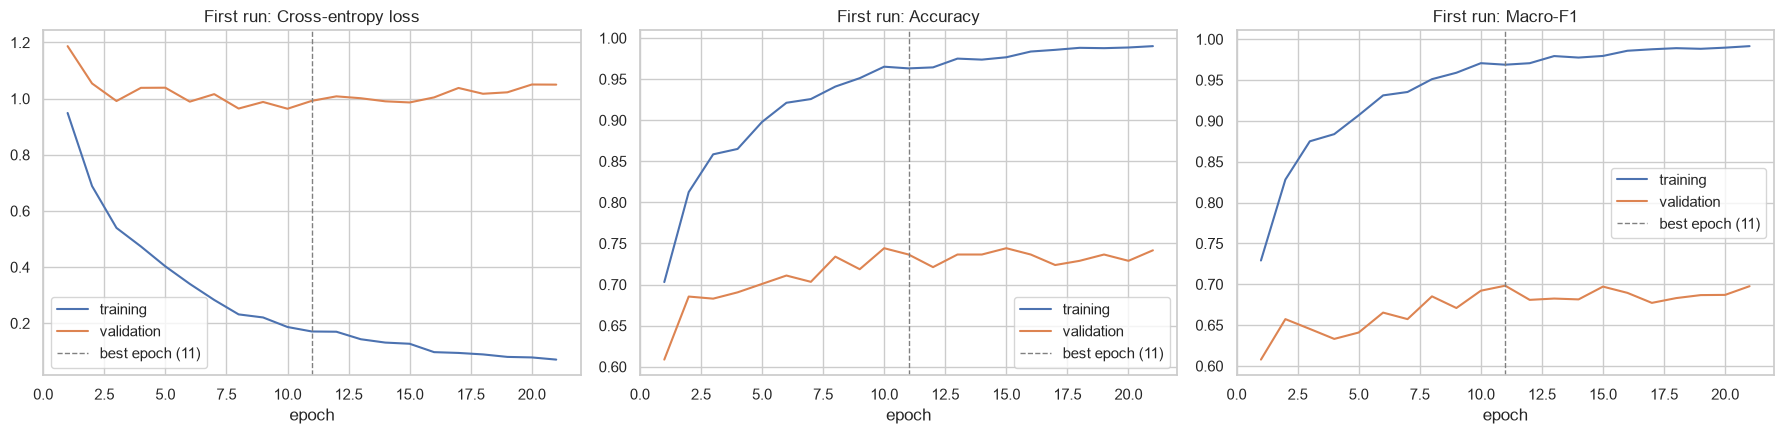

In [6]:
t0 = time.perf_counter()
model, history, best_epoch = train_model(X_tr, y_tr, X_va, y_va, verbose=True)
print(f"Training time: {time.perf_counter() - t0:.1f} s on CPU")
lowest = history.loc[history["val_loss"].idxmin()]
print(f"Lowest validation loss: {lowest['val_loss']:.3f} at epoch {lowest['epoch']:.0f}")
plot_curves(history, best_epoch, "First run", "2_training_curves.png")

**Observations - learning curves**
- Training takes **about 2 seconds** on CPU (output above): ~2,400 examples and ~460,000 weights is a small problem.
- **Training accuracy climbs to 98.9% by epoch 20 while validation accuracy plateaus around 73-74%** (log above). The model *can* nearly memorise the training set despite dropout and weight decay: this growing gap is the overfitting signature.
- **Validation loss is lowest at epoch 10 (0.964, printed above) and then rises, while validation accuracy and macro-F1 stay flat.** The model gets *more confident* without getting more accurate, including on its mistakes, and confident mistakes are exactly what cross-entropy punishes. This is why early stopping watches macro-F1, and restores the best epoch (11, validation macro-F1 0.698).
- **Implication:** the limit is not the model's capacity (it can fit the training data almost perfectly) but how much the embeddings and labels allow it to *generalise*. Bigger models are unlikely to help; the next section checks this.

## 6. Comparing settings

**What:** train variants of the model, each changing **one** setting from the default, and compare them on the **validation** set (the test set is still untouched). Each variant is trained with 3 different seeds, and I report the average and the spread (standard deviation, *std*): differences smaller than the seed-to-seed spread are noise, not real improvements.

**Why these variants:** each tests one choice made in Section 3-4: the class weights (none, or full 1/size), label smoothing, the amount of dropout, and the size of the network (smaller and larger).

In [7]:
variants = {
    "default": {},
    "no class weights": dict(weight_power=0.0),
    "full 1/size class weights": dict(weight_power=1.0),
    "no label smoothing": dict(label_smoothing=0.0),
    "less dropout (0.1, no input dropout)": dict(dropout=0.1, input_dropout=0.0),
    "more dropout (0.5, input 0.2)": dict(dropout=0.5, input_dropout=0.2),
    "smaller: 1 hidden layer (256)": dict(hidden=(256,)),
    "larger: (1024, 256)": dict(hidden=(1024, 256)),
}
rows = []
t0 = time.perf_counter()
for name, change in variants.items():
    cfg = {**DEFAULT_CFG, **change}
    for s in range(3):
        m, _, be = train_model(X_tr, y_tr, X_va, y_va, cfg, seed=s)
        _, acc, f1, _ = evaluate(m, X_va, y_va, nn.CrossEntropyLoss())
        rows.append(dict(variant=name, seed=s, val_acc=acc, val_macro_f1=f1, best_epoch=be))
print(f"Time: {time.perf_counter() - t0:.0f} s")
pd.DataFrame(rows).groupby("variant", sort=False).agg(
    val_acc=("val_acc", "mean"), val_macro_f1=("val_macro_f1", "mean"),
    macro_f1_std=("val_macro_f1", "std"), best_epoch=("best_epoch", "mean")).round(3)

Time: 40 s


,val_acc,val_macro_f1,macro_f1_std,best_epoch
variant,,,,
default,0.746,0.703,0.008,11.000
no class weights,0.754,0.715,0.001,4.000
full 1/size class weights,0.755,0.706,0.008,20.333
no label smoothing,0.760,0.707,0.005,18.000
"less dropout (0.1, no input dropout)",0.759,0.711,0.002,14.000
"more dropout (0.5, input 0.2)",0.744,0.703,0.000,15.333
smaller: 1 hidden layer (256),0.758,0.715,0.006,7.667
"larger: (1024, 256)",0.754,0.708,0.012,20.000


**Observations - settings**
- All eight variants land between **0.703 and 0.715 validation macro-F1**, a 1.2-point range, while the same variant trained with different seeds varies by up to 0.012 (`macro_f1_std`, table above). **No setting makes a clear difference**, consistent with the learning curves: the limit is the data, not the model.
- Details: a network with a single 256-unit layer is as good as the default two layers; a larger one is no better; class weights barely matter (the small categories are among the *best separated* ones in Part 1C, so the model does not ignore them even without weights); removing label smoothing or changing dropout moves results within the noise.
- **Decision: keep the default.** "No class weights" and "smaller" top the table, but by 1.2 points on 391 validation items with 3 seeds; picking the top variant here would mostly be fitting the noise of this particular validation set. The default's choices (mild class weights for the imbalance, label smoothing for the noisy labels, moderate dropout) are justified by Part 1 findings rather than by this small difference.

## 7. Extra training data from paraphrases

**What:** each anchor comes with a `positive`: a text with the same meaning, e.g. *"Cl/F"* → *"Total body clearance"* (Part 1A). If a positive has the same category as its anchor, every training row provides **a second, differently worded example for free**, doubling the training data. This is a form of *data augmentation*.

**Two checks before using them:**
1. **Do positives really share the anchor's category?** The dataset gives no category for positives, but some positive texts also appear elsewhere as anchors, with a category. I compare the two.
2. **No leakage:** a positive is used only if its text does not appear as an anchor in the validation or test set; otherwise the model would be trained on a test text.

Validation and test sets do not change (anchors only), so results stay comparable.

In [8]:
X_pos = np.load("embeddings/positive.npy").astype(np.float32)
pos_groups = df["positive"].str.lower().str.strip().to_numpy()

# Check 1: positives that are also anchors somewhere: same category?
anchor_categories = df.groupby(groups)["case"].agg(set)
found = [(i, anchor_categories[g]) for i, g in enumerate(pos_groups) if g in anchor_categories.index]
same = np.mean([df["case"].iat[i] in cats for i, cats in found])
print(f"Positives that also appear as anchors: {len(found)}; with the same category as their own anchor: {same:.1%}")

# Check 2: drop positives whose text is a validation/test anchor
def augment_with_positives(tr_idx, held_out_idx):
    held_out = set(groups[held_out_idx])
    keep = tr_idx[~np.isin(pos_groups[tr_idx], list(held_out))]
    return (np.concatenate([X_all[tr_idx], X_pos[keep]]), np.concatenate([y_all[tr_idx], y_all[keep]]), len(keep))

X_tr_aug, y_tr_aug, n_pos = augment_with_positives(train_idx, np.concatenate([val_idx, test_idx]))
print(f"Training rows: {len(X_tr)} anchors + {n_pos} positives = {len(X_tr_aug)} "
      f"({len(train_idx) - n_pos} positives dropped because their text is a validation/test anchor)")

rows = []
for name, (Xt, yt) in {"anchors only": (X_tr, y_tr), "anchors + positives": (X_tr_aug, y_tr_aug)}.items():
    for s in range(3):
        m, _, be = train_model(Xt, yt, X_va, y_va, seed=s)
        _, acc, f1, _ = evaluate(m, X_va, y_va, nn.CrossEntropyLoss())
        rows.append(dict(training_data=name, val_acc=acc, val_macro_f1=f1, best_epoch=be))
pd.DataFrame(rows).groupby("training_data").mean().round(3)

Positives that also appear as anchors: 65; with the same category as their own anchor: 98.5%
Training rows: 2438 anchors + 2415 positives = 4853 (23 positives dropped because their text is a validation/test anchor)


,val_acc,val_macro_f1,best_epoch
training_data,,,
anchors + positives,0.746,0.701,7.0
anchors only,0.746,0.703,11.0


**Observations - paraphrases**
- **The "same category" assumption holds**: of the 65 positives that also appear as anchors, 98.5% have the same category as their own anchor (first output). 2,415 positives are added; 23 are dropped because their text is a validation or test anchor.
- **On this validation set, the paraphrases make no difference** (0.746 accuracy either way); the model just reaches its best epoch sooner. One validation set of 391 items cannot settle a small effect, so Section 10 measures it on 5 different splits.

## 8. The final model

**What:** train the final model with the default settings on anchors + positives, with early stopping on validation macro-F1, and save it to `models/endpoint_classifier.pt`. The test set is used **once**, in the next section.

epoch   1 | train loss 0.725 acc 0.804 | val loss 1.021 acc 0.701 macro-F1 0.662 | lr 1.0e-03


epoch   5 | train loss 0.282 acc 0.922 | val loss 1.007 acc 0.716 macro-F1 0.655 | lr 1.0e-03


epoch  10 | train loss 0.115 acc 0.977 | val loss 1.000 acc 0.734 macro-F1 0.682 | lr 5.0e-04


epoch  15 | train loss 0.080 acc 0.988 | val loss 0.996 acc 0.754 macro-F1 0.697 | lr 2.5e-04


epoch  20 | train loss 0.067 acc 0.991 | val loss 1.027 acc 0.742 macro-F1 0.675 | lr 1.3e-04


epoch  25 | train loss 0.062 acc 0.992 | val loss 1.036 acc 0.744 macro-F1 0.680 | lr 6.3e-05
Stopped after epoch 25; best validation macro-F1 0.697 at epoch 15
Training time: 3.1 s on CPU


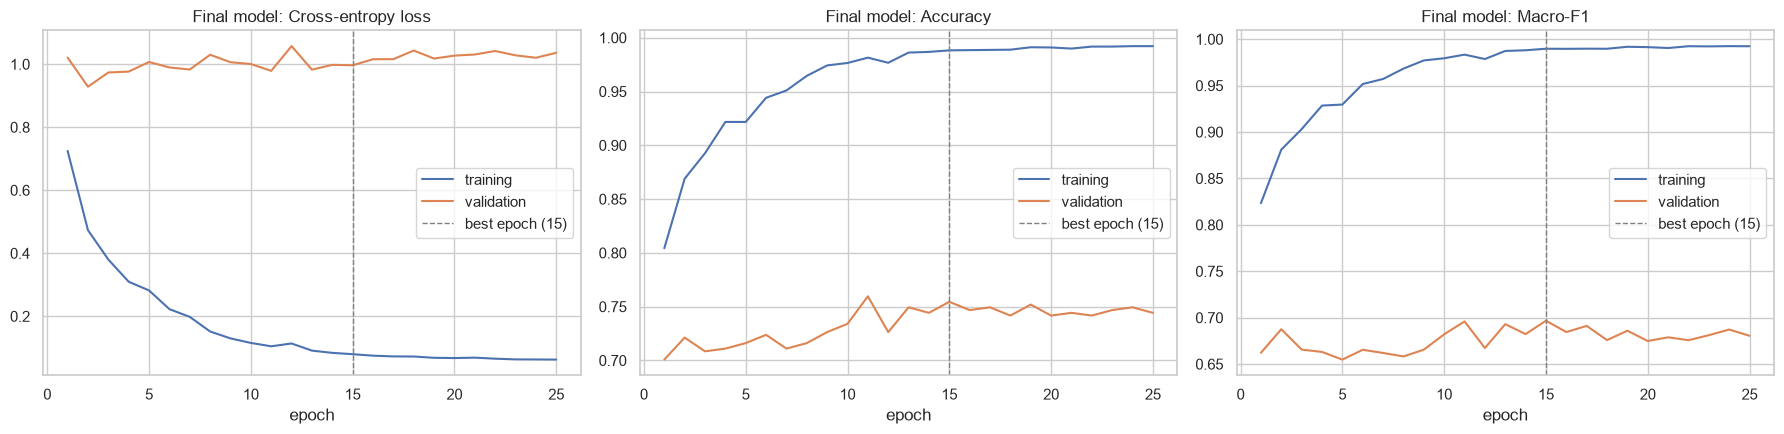

In [9]:
t0 = time.perf_counter()
final_model, final_history, final_best_epoch = train_model(X_tr_aug, y_tr_aug, X_va, y_va, seed=SEED, verbose=True)
print(f"Training time: {time.perf_counter() - t0:.1f} s on CPU")
torch.save({"state_dict": final_model.state_dict(), "config": DEFAULT_CFG, "classes": CLASSES},
           MODEL_DIR / "endpoint_classifier.pt")
plot_curves(final_history, final_best_epoch, "Final model", "2_final_training_curves.png")

**Observations - final model**
- Training stops at epoch 25, keeping epoch 15 (validation macro-F1 0.697), in about 3 seconds (output above). The curves show the same pattern as the first run: training accuracy close to 99%, validation around 74-75%.

## 9. Test set evaluation

**What:** score the final model on the test set, next to the baselines (trained on the same training anchors).

**Why the baselines again:** the validation set was used to make decisions, so the test set gives the first unbiased comparison.

In [10]:
_, _, _, test_proba = evaluate(final_model, X_te, y_te, nn.CrossEntropyLoss())
test_pred = test_proba.argmax(1)

knn = KNeighborsClassifier(10, metric="cosine", weights="distance").fit(X_tr, y_tr)
logreg = LogisticRegression(C=10, max_iter=3000, class_weight="balanced").fit(X_tr, y_tr)
pd.DataFrame({
    "Majority class": scores(y_te, np.full_like(y_te, np.bincount(y_tr).argmax())),
    "kNN (k=10)": scores(y_te, knn.predict(X_te)),
    "Logistic regression": scores(y_te, logreg.predict(X_te)),
    "Neural network (final)": scores(y_te, test_pred),
}).T.round(3)

,accuracy,macro_f1,weighted_f1,balanced_acc
Majority class,0.291,0.050,0.132,0.111
kNN (k=10),0.671,0.681,0.657,0.682
Logistic regression,0.611,0.606,0.603,0.653
Neural network (final),0.711,0.683,0.707,0.689


**What:** the per-category report.

**How to read it:** for each category, **precision** (of the items predicted as this category, the share that really are), **recall** (of the items that really are this category, the share found), **F1** (the balance of the two) and **support** (how many test items the category has; small supports mean noisy scores). The bottom rows are the overall accuracy, the plain average over categories (*macro avg*) and the size-weighted average (*weighted avg*).

In [11]:
print(classification_report(y_te, test_pred, target_names=CLASSES, digits=3))

                 precision    recall  f1-score   support

   General Case      0.611     0.569     0.589       116
       COA Tool      0.771     0.900     0.831        90
Pharmacokinetic      0.862     0.781     0.820        64
  Adverse Event      0.793     0.639     0.708        36
  Complications      0.615     0.667     0.640        24
 Immunogenicity      0.609     0.700     0.651        20
           Cost      0.714     0.833     0.769        18
      Mortality      0.700     0.778     0.737        18
    Demographic      0.500     0.333     0.400        12

       accuracy                          0.711       398
      macro avg      0.686     0.689     0.683       398
   weighted avg      0.710     0.711     0.707       398



**What:** the **confusion matrix**: for each true category (row), how its test items were predicted (column).

**How to read it:** the **diagonal** holds the correct predictions; every cell **off the diagonal** is a specific mistake, e.g. row *Demographic*, column *General Case* = Demographic items predicted as General Case. The left chart shows counts; the right one shows each row as percentages, so the diagonal is each category's recall and the categories can be compared regardless of size. Below the charts, the most frequent mistakes are listed.

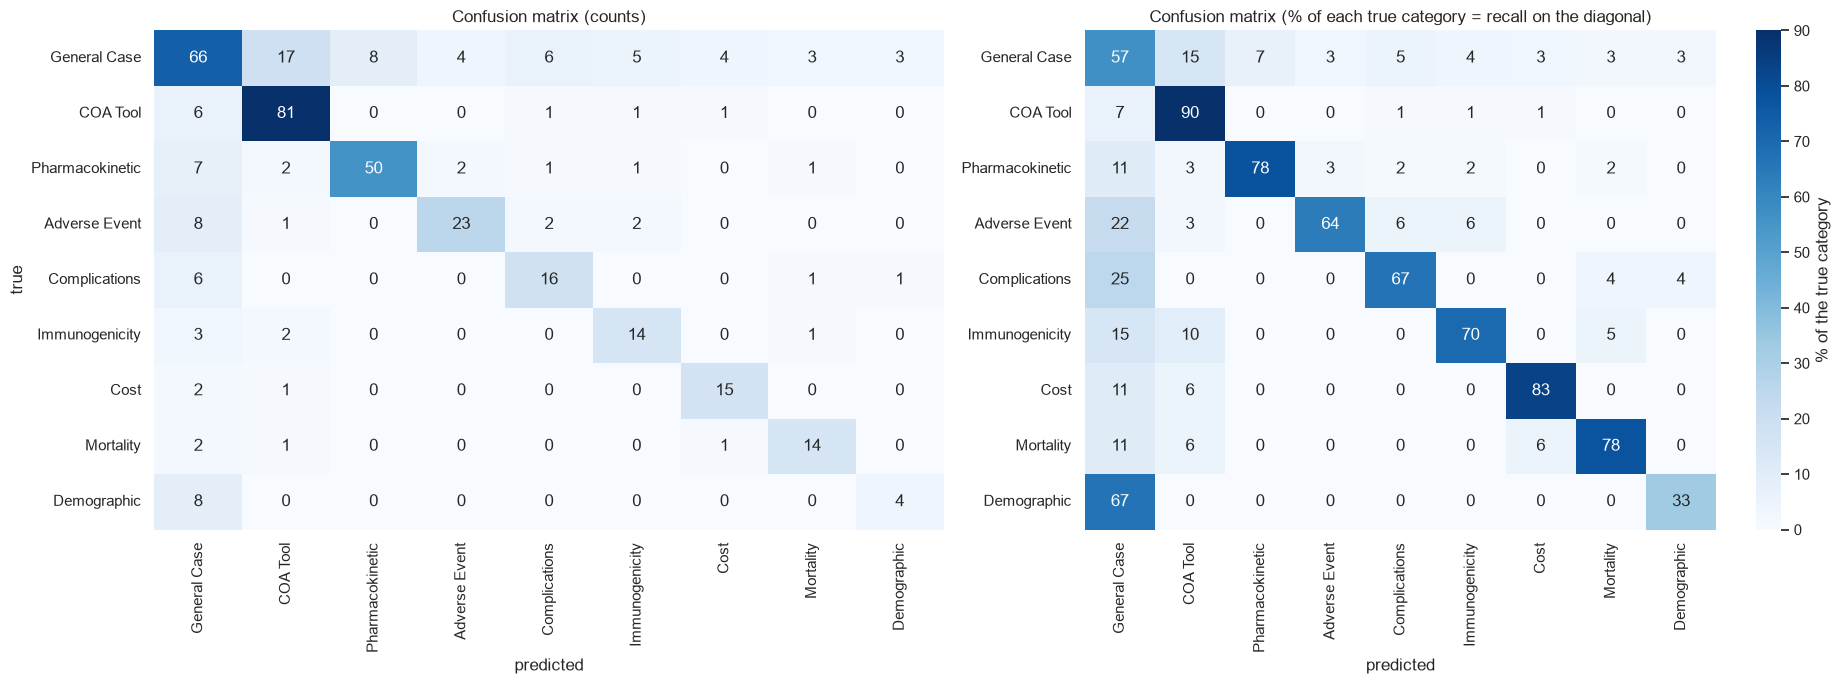

Mistakes: 115 of 398 test items; involving General Case (as true or predicted): 92 (80%)
Most frequent mistakes:
           true       predicted  count
   General Case        COA Tool     17
   General Case Pharmacokinetic      8
  Adverse Event    General Case      8
    Demographic    General Case      8
Pharmacokinetic    General Case      7
   General Case   Complications      6
       COA Tool    General Case      6
  Complications    General Case      6


In [12]:
cm = confusion_matrix(y_te, test_pred)
cm_pct = cm / cm.sum(axis=1, keepdims=True) * 100
fig, axes = plt.subplots(1, 2, figsize=(19, 7))
sns.heatmap(cm, annot=True, fmt="d", cmap="Blues", xticklabels=CLASSES, yticklabels=CLASSES, ax=axes[0], cbar=False)
axes[0].set(title="Confusion matrix (counts)", xlabel="predicted", ylabel="true")
sns.heatmap(cm_pct, annot=True, fmt=".0f", cmap="Blues", xticklabels=CLASSES, yticklabels=CLASSES, ax=axes[1],
            cbar_kws={"label": "% of the true category"})
axes[1].set(title="Confusion matrix (% of each true category = recall on the diagonal)", xlabel="predicted", ylabel="")
plt.tight_layout(); plt.savefig(FIG_DIR / "2_confusion_matrix.png", dpi=120); plt.show()

mistakes = pd.DataFrame([(CLASSES[i], CLASSES[j], cm[i, j]) for i in range(9) for j in range(9) if i != j and cm[i, j]],
                        columns=["true", "predicted", "count"]).sort_values("count", ascending=False)
n_err = mistakes["count"].sum()
n_gc = mistakes.loc[(mistakes["true"] == "General Case") | (mistakes["predicted"] == "General Case"), "count"].sum()
print(f"Mistakes: {n_err} of {len(y_te)} test items; involving General Case (as true or predicted): {n_gc} ({n_gc / n_err:.0%})")
print("Most frequent mistakes:")
print(mistakes.head(8).to_string(index=False))

**What:** compare each category's test F1 with its **kNN purity** from Part 1C (the share of an anchor's 10 nearest neighbours with the same category, recomputed here on the same data).

**Why:** Part 1C predicted which categories would be hard from the shape of the embedding space alone. If the prediction holds, the classifier's difficulties come from the embeddings, not from the classifier.

**How to read it:** one bubble per category; bubble size = number of distinct training anchors. If the points line up from bottom left to top right, purity predicts performance; *r* (correlation) measures how well they line up, from 0 (no relation) to 1 (perfectly aligned).

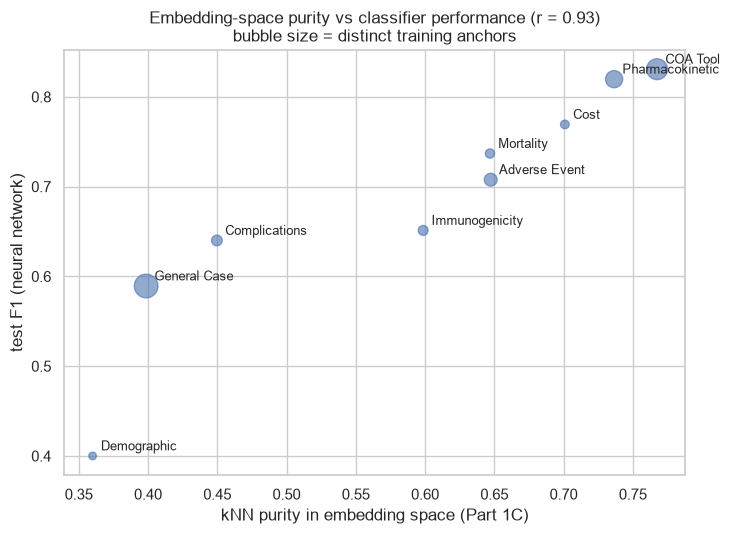

Correlation r = 0.93


,test_f1,test_items,knn_purity_1C,distinct_train_anchors
COA Tool,0.831,90,0.767,453
Pharmacokinetic,0.820,64,0.736,306
Cost,0.769,18,0.701,78
Mortality,0.737,18,0.647,89
Adverse Event,0.708,36,0.647,171
Immunogenicity,0.651,20,0.599,102
Complications,0.640,24,0.450,119
General Case,0.589,116,0.399,582
Demographic,0.400,12,0.360,61


In [13]:
uniq = df.drop_duplicates(["anchor", "case"])
E, yu = X_all[uniq.index], y_all[uniq.index]
_, nn_idx = NearestNeighbors(n_neighbors=11, metric="cosine").fit(E).kneighbors(E)
purity = pd.Series((yu[nn_idx[:, 1:]] == yu[:, None]).mean(1)).groupby(yu).mean()

per_class = pd.DataFrame({
    "test_f1": f1_score(y_te, test_pred, average=None),
    "test_items": np.bincount(y_te, minlength=9),
    "knn_purity_1C": purity.to_numpy(),
    "distinct_train_anchors": [len(set(groups[train_idx][y_all[train_idx] == k])) for k in range(9)],
}, index=CLASSES)
r = np.corrcoef(per_class["knn_purity_1C"], per_class["test_f1"])[0, 1]

fig, ax = plt.subplots(figsize=(7.5, 5.5))
ax.scatter(per_class["knn_purity_1C"], per_class["test_f1"], s=per_class["distinct_train_anchors"] / 2, alpha=0.6)
for c, row in per_class.iterrows():
    ax.annotate(c, (row["knn_purity_1C"], row["test_f1"]), xytext=(6, 4), textcoords="offset points", fontsize=9)
ax.set(xlabel="kNN purity in embedding space (Part 1C)", ylabel="test F1 (neural network)",
       title=f"Embedding-space purity vs classifier performance (r = {r:.2f})\nbubble size = distinct training anchors")
plt.tight_layout(); plt.savefig(FIG_DIR / "2_f1_vs_purity.png", dpi=120); plt.show()
print(f"Correlation r = {r:.2f}")
per_class.sort_values("test_f1", ascending=False).round(3)

**What:** two more breakdowns of the test results:
- **real vs synthetic** test items (`is_synthetic`, Part 1A), to see whether real endpoints are harder;
- **accuracy by confidence**: the model outputs a probability for each category; the highest one is its *confidence*. Grouping test items by confidence shows whether a confident prediction is more often right, which would make confidence useful in practice (e.g. sending low-confidence predictions to a human, or to a more capable but slower and more expensive model such as an LLM).

              accuracy  items
is_synthetic                 
False            0.757     37
True             0.706    361 

            accuracy  items  share_of_test
conf                                      
(0.0, 0.5]     0.062     32          0.080
(0.5, 0.7]     0.392     51          0.128
(0.7, 0.9]     0.611     72          0.181
(0.9, 1.0]     0.893    243          0.611


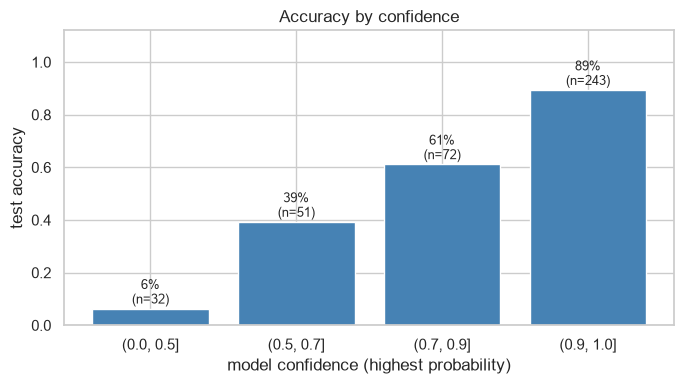

In [14]:
test_df = df.loc[test_idx].assign(pred=[CLASSES[k] for k in test_pred], conf=test_proba.max(1),
                                  correct=test_pred == y_te)
print(test_df.groupby("is_synthetic")["correct"].agg(["mean", "size"])
      .rename(columns={"mean": "accuracy", "size": "items"}).round(3).to_string(), "\n")

conf_tab = test_df.groupby(pd.cut(test_df["conf"], [0, 0.5, 0.7, 0.9, 1.0]), observed=True)["correct"].agg(["mean", "size"])
conf_tab.columns = ["accuracy", "items"]
conf_tab["share_of_test"] = conf_tab["items"] / len(test_df)
print(conf_tab.round(3).to_string())

fig, ax = plt.subplots(figsize=(7, 4))
ax.bar(conf_tab.index.astype(str), conf_tab["accuracy"], color="steelblue")
for i, (acc, n) in enumerate(zip(conf_tab["accuracy"], conf_tab["items"])):
    ax.text(i, acc + 0.02, f"{acc:.0%}\n(n={n})", ha="center", fontsize=9)
ax.set(ylim=(0, 1.12), xlabel="model confidence (highest probability)", ylabel="test accuracy",
       title="Accuracy by confidence")
plt.tight_layout(); plt.savefig(FIG_DIR / "2_confidence.png", dpi=120); plt.show()

**Observations - test results**
- **Overall** (first table): the neural network reaches **71.1% accuracy and 0.683 macro-F1** on this split's test set, versus 67.1% / 0.681 for kNN, 61.1% / 0.606 for logistic regression and 29.1% for the majority class. It beats kNN clearly on accuracy but only marginally on macro-F1 *on this split*; Section 10 shows a clearer margin on average.
- **Best categories** (report): **COA Tool (F1 0.831) and Pharmacokinetic (0.820)**, then Cost (0.769) and Mortality (0.737). **Worst: Demographic (0.400), General Case (0.589) and Complications (0.640)**, exactly the three Part 1C predicted as hardest.
- **General Case is at the centre of the errors** (confusion matrix): **92 of the 115 mistakes (80%) involve it**, as the true or the predicted category. The most frequent single mistake is General Case → COA Tool (17), and 8 of the 12 Demographic items are predicted as General Case.
- **Part 1C predicted this**: per-category test F1 follows the embedding-space kNN purity with a **correlation of r = 0.93** (scatter plot). The classifier mostly inherits the structure of the embedding space.
- **Real test items are not harder**: 75.7% accuracy on the 37 real ones vs 70.6% on the 361 synthetic ones (too few real items to read much into the difference).
- **Confidence is informative**: the 61% of test items predicted with confidence above 0.9 are **89.3% correct**, while the 8% below 0.5 are almost always wrong (6.2% correct) (confidence table).

## 10. Robustness, and the cost of a careless split

**What:** repeat the whole pipeline (new split → train → test) with 5 different seeds, in three setups:
- grouped split, anchors only;
- grouped split, anchors + positives (the final setup);
- a **careless split**: a plain stratified split of rows that ignores repeated anchors (with positives).

**Why:** a test set of ~400 endpoints gives a noisy estimate; averaging over 5 splits gives a more reliable one. Comparing the first two setups split by split tells whether the paraphrases really help. The third setup measures how much a careless split would **inflate** the results, because identical anchors land in both training and test.

In [15]:
def run_pipeline(seed, careless=False, augment=True):
    if careless:
        trv, te = train_test_split(np.arange(len(df)), test_size=0.15, stratify=y_all, random_state=seed)
        tr, va = train_test_split(trv, test_size=0.176, stratify=y_all[trv], random_state=seed)
    else:
        tr, va, te = make_splits(seed)
    Xt, yt = augment_with_positives(tr, np.concatenate([va, te]))[:2] if augment else (X_all[tr], y_all[tr])
    m, _, _ = train_model(Xt, yt, X_all[va], y_all[va], seed=seed)
    _, _, _, p = evaluate(m, X_all[te], y_all[te], nn.CrossEntropyLoss())
    knn_pred = KNeighborsClassifier(10, metric="cosine", weights="distance").fit(X_all[tr], y_all[tr]).predict(X_all[te])
    return {"neural network": scores(y_all[te], p.argmax(1)), "kNN": scores(y_all[te], knn_pred)}

setups = {"grouped, anchors only": dict(augment=False),
          "grouped, + positives (final)": dict(),
          "CARELESS row split, + positives": dict(careless=True)}
rows = []
t0 = time.perf_counter()
for setup, kw in setups.items():
    for s in range(5):
        for model_name, sc in run_pipeline(s, **kw).items():
            rows.append(dict(setup=setup, model=model_name, seed=s, **sc))
print(f"Time: {time.perf_counter() - t0:.0f} s")
rob = pd.DataFrame(rows)
rob.groupby(["setup", "model"], sort=False)[["accuracy", "macro_f1"]].agg(["mean", "std"]).round(3)

Time: 40 s


accuracy        macro_f1       
                                                   mean    std     mean    std
setup                           model                                         
grouped, anchors only           neural network    0.718  0.017    0.706  0.037
                                kNN               0.685  0.013    0.672  0.026
grouped, + positives (final)    neural network    0.739  0.023    0.716  0.030
                                kNN               0.685  0.013    0.672  0.026
CARELESS row split, + positives neural network    0.807  0.014    0.823  0.017
                                kNN               0.766  0.020    0.797  0.018

**What:** the neural network's test results split by split, and the effect of adding the positives on each split (difference between the two grouped setups, in percentage points).

In [16]:
nn_rob = rob[rob["model"] == "neural network"].pivot(index="seed", columns="setup", values=["accuracy", "macro_f1"])
gain = pd.DataFrame({
    "accuracy, anchors only": nn_rob[("accuracy", "grouped, anchors only")],
    "accuracy, + positives": nn_rob[("accuracy", "grouped, + positives (final)")],
    "gain (points)": (nn_rob[("accuracy", "grouped, + positives (final)")]
                      - nn_rob[("accuracy", "grouped, anchors only")]) * 100,
    "macro-F1 gain (points)": (nn_rob[("macro_f1", "grouped, + positives (final)")]
                               - nn_rob[("macro_f1", "grouped, anchors only")]) * 100,
})
gain.round(3)

,"accuracy, anchors only","accuracy, + positives",gain (points),macro-F1 gain (points)
seed,,,,
0,0.699,0.742,4.293,3.492
1,0.742,0.757,1.519,-2.248
2,0.711,0.706,-0.508,-0.030
3,0.730,0.728,-0.254,0.144
4,0.709,0.762,5.316,3.287


**Observations - robustness and leakage** (tables above)
- **On average over 5 splits, the final setup reaches 73.9% ± 2.3 accuracy and 0.716 ± 0.030 macro-F1**, versus 68.5% / 0.672 for kNN. The seed-42 split of Section 9 (71.1%) was one of the harder ones; the 5-split average is the more reliable estimate.
- **The paraphrases help a little, inconsistently**: accuracy gains of +4.3, +1.5, −0.5, −0.3 and +5.3 points on the 5 splits (+2.1 on average), and macro-F1 gains between −2.2 and +3.5 points (+0.9 on average). I keep them in the final setup because the average effect is positive and they add wording variety (abbreviation ↔ full name, synonyms), but this is a **modest, not proven** improvement.
- **A careless split inflates the results**: ignoring repeated anchors, the same pipeline reports **80.7% accuracy and 0.823 macro-F1**, **+6.8 points of accuracy and +10.7 points of macro-F1** that come from test texts already seen in training, not from better classification. The inflation is largest on macro-F1 because the repeated anchors are concentrated in the small categories (Part 1A). Even kNN jumps from 68.5% to 76.6%.
- **About the README's expected 75-85%:** the careless-split numbers fall inside that range, while the grouped-split ones are ~1-2 points below it. I report **~74% as the honest estimate for new, unseen endpoints**; the 80% figure answers a different question ("how well are already-seen endpoints recognised?").

## 11. Interpretation

**Performance.** The final neural network classifies **new, unseen endpoint texts with ~74% accuracy and ~0.72 macro-F1** (average over 5 splits, Section 10), well above always answering General Case (~29%), logistic regression (~61-64%) and the 10-nearest-neighbours vote (~68-70%). The training curves show that the network can fit its training data almost perfectly (99%), and no change of settings moves validation performance beyond noise (Sections 5-6): **the ceiling is set by the embeddings and the labels, not by the classifier**. The model's confidence is also usable: predictions above 0.9 confidence, 61% of the test set, are 89% correct, so in practice the classifier could handle the confident cases on its own and send the low-confidence ones to a human for review, or to a more capable but slower and more expensive model such as an LLM, which knows things the embeddings may miss (drug names, instrument acronyms). This was not tested here; it would need to be measured on the same test set (Section 9).

**Best and worst categories.** **COA Tool (F1 0.83) and Pharmacokinetic (0.82)** are classified best: they have distinctive wording (named instruments; *AUC*, *Cmax*, *concentration*, Part 1A) and the tightest neighbourhoods in the embedding space (Part 1C). **Demographic (0.40), General Case (0.59) and Complications (0.64)** are the worst. One pattern dominates the mistakes: **80% of them involve General Case**. Two thirds of the Demographic test items are predicted as General Case, and the most frequent single mistake is General Case → COA Tool, for assessment-like wording that is not a named instrument. General Case behaves as a catch-all that overlaps every other category; Demographic has the fewest distinct training examples (61) and many endpoints that are ambiguous out of context.

**Connection to the embedding analysis (Part 1C).** Part 1C predicted these results from the embedding space alone: per-category test F1 follows the kNN purity measured there with **r = 0.93**, and the three categories with the lowest purity are exactly the three worst-classified. The "neighbourhoods leak into General Case" pattern of Part 1C reappears as the dominant column of the confusion matrix. The classifier draws better boundaries than a neighbour vote, but it cannot separate what the embeddings place together.

**Possible improvements**, by expected impact:
1. **Clarify the General Case boundary**, where most errors are: clearer labelling guidelines, or a two-step classifier (first "specific category vs General Case", with a tuned threshold, then the specific category).
2. **More distinct examples for the small categories**, especially Demographic, instead of repeated anchors.
3. **Clean the labels**: the conflicting and suspicious labels found in Part 1A.
4. **Fine-tune the embedding model itself with the category labels** (end-to-end, or with triplets whose negatives come from easily confused categories), since it was trained to group paraphrases, not categories (Part 1A).
5. **Use the confidence score** to route uncertain predictions to human review or to an LLM, keeping the fast classifier for the confident majority.